# Eye v1.1

The working notebook for the next version of eye. `eye_v1.ipynb` built v1 and `eye_v1_challenges.ipynb` answered the October review. New tests go here, one section each.

**Population:** the same as the challenges notebook.

- D1 2022–2026 from the pipeline_v2 season parquets.
- Bunts are removed.
- The production model code (`backend/models/eye_v1.py`) is used, trained on verified games and scored on every game.
- Height is still ignored.

Runtime: about 15 minutes, since every season is refit. LightGBM's multithreaded fits aren't bit-identical from run to run, so a re-run can move numbers in the third decimal.

## Section 1. Contact xRV and borderline takes (Nov 2, 2026)

**The challenge.** In the test plate appearance, a hitter who walks by taking a 3-2 pitch 0.5 in off the outer edge scores **−0.22** runs. A hitter who strikes out swinging at a 3-2 pitch down the middle scores **+0.02**. From a coach's view the take should be rewarded, because a swing on the outer edge rarely produces good contact. That raises two questions:

1. Does eye price a swing as if contact were equally good everywhere? If we add an xRV on contact that depends on where the pitch is, does eye change much?
2. Should laying off a borderline pitch count for more than fighting it off?

| Part | Question |
|---|---|
| 1a | What EV(swing) already contains |
| 1b | Contact xRV by plate location |
| 1c | EV(swing) rebuilt from whiff, foul and contact xRV |
| 1d | The test plate appearance, rescored |
| 1e | Why the 3-2 borderline take still loses |
| 1f | A rulebook-zone version of eye |
| 1g | Which version measures eye better |

### Setup

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import lightgbm as lgb
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from sklearn.model_selection import GroupShuffleSplit

# repo root = the first folder up from here that holds pipeline_v2
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pipeline_v2").is_dir())
sys.path.insert(0, str(REPO))
from backend.models import eye_v1, rv_store, cq_store, contact_quality as cq
from delispice_app.report import ZONE   # the app's zone: 1.5-3.38 ft high, +/-0.83 ft wide (ball radius included)

SEASONS = REPO / "pipeline_v2" / "serving" / "pitches" / "D1"
YEARS = ["2022", "2023", "2024", "2025", "2026"]
MIN_N = 200    # decisions a hitter needs in a season to enter the hitter-level comparisons
BALL = 2.9 / 12                                  # one baseball, in feet
MID = (ZONE["b"] + ZONE["t"]) / 2                # mid-zone height

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_float_precision(3)
pl.Config.set_tbl_hide_dataframe_shape(True)

# chart style: recessive axes, one blue for single series, blue <-> red around gray for differences
BLUE, ORANGE, INK, MUTED, GRAY = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#a3a29c"
SEQ = LinearSegmentedColormap.from_list("seq", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#f19c9b", "#c23b3a"])
plt.rcParams.update({"axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.titlecolor": INK, "axes.titlesize": 11,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

### 1a. What EV(swing) already contains

In v1, EV(swing) is one LightGBM regression. Its target is each swing's **realized run value**, and its inputs are location, count, pitch family and batter side. The realized run value of a ball in play is what the contact actually produced. A rolled-over grounder on the outer edge enters as an out (about −0.4 runs) at that location. So **contact quality by location is already in v1**, but only implicitly and with noise: a line drive caught by the shortstop counts as an out too.

This section makes it explicit. A swing has three outcomes:

$$\text{EV(swing)} = P(\text{whiff})\cdot rv_\text{strike} + P(\text{foul})\cdot rv_\text{foul} + P(\text{in play})\cdot \text{xRV}_\text{contact}$$

- **`rv_strike`** comes from the count table, the same one EV(take) uses.
- **`rv_foul`** is the same as `rv_strike` before two strikes and 0 with two strikes, because the count doesn't change.
- **`xRV_contact`** is the expected value of a ball in play at that location and count. Each ball in play is first scored by the shipped contact-quality model (`cq_D1_{year}`: exit velocity, launch angle, direction → P(out, 1B, 2B, 3B, HR)), in place of what actually happened to it. A LightGBM then learns the average by location, count, family and side.

Each outcome is valued **in its own count**. An out at 3-0 costs about twice what it does at 0-2, because the 3-0 count it erases was worth more.

In [2]:
COLS = ["PitchUID", "GameUID", "Batter", "BatterSide", "AutoPitchType", "TaggedHitType", "Balls", "Strikes",
        "PitchCall", "KorBB", "PlayResult", "ExitSpeed", "Angle", "Direction", "PlateLocHeight", "PlateLocSide",
        "is_verified", *rv_store.ROW_STATE]
KEEP = ["PitchUID", "GameUID", "Batter", "BatterSide", "Balls", "Strikes", "PitchCall", "PlayResult",
        "ExitSpeed", "Angle", "Direction", "PlateLocHeight", "PlateLocSide", "PitchFamily", "swung",
        "run_value", "is_verified", "in_zone", "outc"]
IN_ZONE = (pl.col("PlateLocSide").abs() <= ZONE["h"]) & pl.col("PlateLocHeight").is_between(ZONE["b"], ZONE["t"])
# swing outcome classes for the outcome model: 0 whiff, 1 foul, 2 ball in play (null for takes)
OUTC = (pl.when(pl.col("swung") == 0).then(None)
          .when(pl.col("PitchCall") == "StrikeSwinging").then(0)
          .when(pl.col("PitchCall") == "InPlay").then(2).otherwise(1))
CLASSES = list(cq.LABEL_MAP)   # the contact model's classes: Out, Single, Double, Triple, HomeRun


def load_season(year):
    """Every D1 pitch of one season, with its realized run value in that season's RE288."""
    raw = pl.read_parquet(SEASONS / year / f"d1_{year}.parquet", columns=COLS)
    return raw.with_columns(rv_store.attach_rv(raw, "D1", year).alias("run_value"))


def decisions(raw):
    """Production's prepare(), bunts removed, plus the rulebook-zone flag and the swing outcome class."""
    d = eye_v1.prepare(raw).filter(~pl.col("TaggedHitType").eq_missing("Bunt"))
    return d.with_columns(IN_ZONE.alias("in_zone"), OUTC.alias("outc")).select(KEEP)


def outcomes(raw):
    """Per hitter-season results from EVERY pitch: walk %, strikeout %, realized RV/100 pitches."""
    pa_end = pl.col("KorBB").is_in(["Walk", "Strikeout"]) | pl.col("PitchCall").is_in(["InPlay", "HitByPitch"])
    return raw.unique("PitchUID").group_by("Batter").agg(
        ((pl.col("KorBB") == "Walk").sum() / pa_end.sum()).alias("bb"),
        ((pl.col("KorBB") == "Strikeout").sum() / pa_end.sum()).alias("k"),
        (pl.col("run_value").mean() * 100).alias("rv100"))


def outcome_values(ip):
    """(4, 3, 5) array: the mean run value of each contact class (out ... HR) in each count, from one
    season's balls in play. A rare class missing from a count falls back to its all-count mean."""
    t = (ip.filter(pl.col("PlayResult").is_in(CLASSES))
           .with_columns(pl.col("PlayResult").replace_strict(cq.LABEL_MAP).alias("k")))
    V = np.full((4, 3, 5), np.nan)
    for b, s, k, v in t.group_by("Balls", "Strikes", "k").agg(pl.col("run_value").mean()).iter_rows():
        V[b, s, k] = v
    overall = t.group_by("k").agg(pl.col("run_value").mean()).sort("k")["run_value"].to_numpy()
    return np.where(np.isnan(V), overall, V)


def contact_xrv(ip, year, V):
    """Each ball in play's xRV in its own count: P(out, 1B, 2B, 3B, HR | EV, LA, direction) from the shipped
    contact model, times that count's outcome values. The ~2% with no tracked EV/LA/direction keep their
    realized run value."""
    cqm = cq_store.load("D1", year)
    X = ip.select("ExitSpeed", "Angle", "Direction").to_numpy().astype(float)
    xrv = ip["run_value"].to_numpy().astype(float).copy()
    vals = V[ip["Balls"].to_numpy(), ip["Strikes"].to_numpy()]
    idx = np.where(~np.isnan(X).any(axis=1))[0]
    for i in range(0, len(idx), 25_000):          # chunked: the model looks up k=800 neighbors per ball
        j = idx[i:i + 25_000]
        xrv[j] = (cqm.predict_proba(X[j]) * vals[j]).sum(axis=1)
    return xrv

`SwingValue` holds the two new models. Tree counts were set by early stopping on a 2026 game split, as production did: 370 for the outcome model and 150 for the contact model. The other settings are production's smooth-surface config (`eye_v1.LGB_PARAMS`).

In [3]:
FEATS = eye_v1.EV_FEATS
CX_TREES = {"outcome": 370, "contact": 150}


def lgb_frame(f):
    p = f.select(FEATS).to_pandas()
    p["PitchFamily"] = p["PitchFamily"].astype(pd.CategoricalDtype(eye_v1.FAM_CATS))
    return p


class SwingValue:
    """EV(swing) from its parts: P(whiff / foul / in play) by location, and the contact xRV of a ball in play there."""

    def fit(self, sw, ip):
        """`sw`: swings with an `outc` class. `ip`: the balls in play among them, with an `xrv_obs` column."""
        self.outcome = lgb.LGBMClassifier(objective="multiclass", n_estimators=CX_TREES["outcome"],
                                          **eye_v1.LGB_PARAMS).fit(lgb_frame(sw), sw["outc"].to_numpy())
        self.contact = lgb.LGBMRegressor(objective="regression", n_estimators=CX_TREES["contact"],
                                         **eye_v1.LGB_PARAMS).fit(lgb_frame(ip), ip["xrv_obs"].to_numpy())
        return self

    def predict(self, c):
        """`c` is EyeModel.components() output, which already carries the count's rv_strike."""
        X = lgb_frame(c)
        p = self.outcome.predict_proba(X)
        xc = self.contact.predict(X)
        rs = c["rv_strike"].to_numpy()
        foul = np.where(c["Strikes"].to_numpy() < 2, rs, 0.0)     # a 2-strike foul leaves the count alone
        return c.with_columns(pl.Series("p_whiff", p[:, 0]), pl.Series("p_foul", p[:, 1]),
                              pl.Series("p_inplay", p[:, 2]), pl.Series("xrv_contact", xc),
                              pl.Series("ev_swing_cx", p[:, 0] * rs + p[:, 1] * foul + p[:, 2] * xc))

### Fit every season

Each season gets the production `EyeModel` and a `SwingValue`. Every decision is scored four ways, all with the same formula, `(swung − P(swing)) × (EV(swing) − EV(take))`:

| Column | EV(swing) | EV(take) |
|---|---|---|
| `eye` | v1 (realized run value) | umpire model |
| `eye_cx` | **contact-built** | umpire model |
| `eye_rule` | v1 | **rulebook zone** (section 1f) |
| `eye_both` | **contact-built** | **rulebook zone** |

In [4]:
VARIANTS = {"eye": "v1 (bunts out)", "eye_cx": "contact xRV", "eye_rule": "rulebook takes", "eye_both": "both"}
# scoring converts the frame to pandas, so pass only what the models and the hitter table need
SCORE_COLS = ["Batter", "BatterSide", "Balls", "Strikes", "PlateLocHeight", "PlateLocSide", "PitchFamily",
              "swung", "in_zone"]


def fit_and_score(year, d):
    count_rv = eye_v1.count_run_values(eye_v1.load_re_matrix("D1", year))
    train = d.filter(pl.col("is_verified"))
    base = eye_v1.EyeModel().fit(train, count_rv)
    sw = train.filter((pl.col("swung") == 1) & pl.col("run_value").is_not_null())
    ip = sw.filter(pl.col("outc") == 2)
    V = outcome_values(ip)
    ip = ip.with_columns(pl.Series("xrv_obs", contact_xrv(ip, year, V)))
    cx = SwingValue().fit(sw, ip)
    dev = pl.col("swung") - pl.col("p_swing")
    s = (cx.predict(base.components(d.select(SCORE_COLS)))
           .with_columns(pl.when(pl.col("in_zone")).then(pl.col("rv_strike")).otherwise(pl.col("rv_ball"))
                           .alias("ev_take_rule"))
           .with_columns((dev * (pl.col("ev_swing") - pl.col("ev_take"))).alias("eye"),
                         (dev * (pl.col("ev_swing_cx") - pl.col("ev_take"))).alias("eye_cx"),
                         (dev * (pl.col("ev_swing") - pl.col("ev_take_rule"))).alias("eye_rule"),
                         (dev * (pl.col("ev_swing_cx") - pl.col("ev_take_rule"))).alias("eye_both")))
    return base, cx, V, ip, s


def per_hitter(s):
    return s.group_by("Batter").agg(pl.len().alias("n"), *[(pl.col(v).mean() * 100).alias(v) for v in VARIANTS],
                                    pl.col("swung").filter(~pl.col("in_zone")).mean().alias("chase"))


# 3-2 pitches at mid height (2.0-2.9 ft), for the real-outcome check in 1e. `off_in` = inches off the
# OUTER edge (negative = still over the plate); away is -side for a righty and +side for a lefty.
EDGE_32 = []
H = {}
for y in YEARS:
    t0 = time.time()
    raw = load_season(y)
    d, out = decisions(raw), outcomes(raw)
    del raw
    base, cx, V, ip, s = fit_and_score(y, d)
    H[y] = per_hitter(s).join(out, on="Batter", how="left")
    away = pl.when(pl.col("BatterSide") == 0).then(-pl.col("PlateLocSide")).otherwise(pl.col("PlateLocSide"))
    EDGE_32.append(d.filter((pl.col("Balls") == 3) & (pl.col("Strikes") == 2),
                            pl.col("PlateLocHeight").is_between(2.0, 2.9))
                     .select(((away - ZONE["h"]) * 12).alias("off_in"), "swung", "PitchCall", "run_value"))
    if y == "2026":
        D26, IP26, V26, BASE, CX = d, ip, V, base, cx
    print(f"{y}: {s.height:,} decisions, {ip.height:,} balls in play, {time.time() - t0:.0f}s")
    del s
EDGE_32 = pl.concat(EDGE_32)

2022: 815,696 decisions, 138,979 balls in play, 44s


2023: 1,120,768 decisions, 187,728 balls in play, 59s


2024: 1,421,243 decisions, 237,183 balls in play, 78s


2025: 1,720,776 decisions, 290,031 balls in play, 95s


2026: 1,944,622 decisions, 327,952 balls in play, 101s


Sanity checks on 2026. The decomposition assumes a whiff is worth `rv_strike` and a foul is worth `rv_strike` before two strikes and 0 after. The realized run values should agree.

In [5]:
crv26 = eye_v1.count_run_values(eye_v1.load_re_matrix("D1", "2026"))
chk = (D26.filter(pl.col("swung") == 1, pl.col("outc") < 2, pl.col("run_value").is_not_null())
          .join(crv26, on=["Balls", "Strikes"])
          .with_columns(pl.when(pl.col("outc") == 0).then(pl.col("rv_strike"))
                          .when(pl.col("Strikes") < 2).then(pl.col("rv_strike")).otherwise(0.0).alias("assumed"))
          .group_by(pl.col("outc").replace_strict({0: "whiff", 1: "foul"}).alias("outcome"),
                    (pl.col("Strikes") == 2).alias("two_strikes"))
          .agg(pl.len().alias("n"), pl.col("run_value").mean().alias("realized"), pl.col("assumed").mean())
          .sort("outcome", "two_strikes"))
print(chk)
print("\nValue of an out and a single in each count (2026):")
print(pl.DataFrame([{"count": f"{b}-{s}", "out": V26[b, s, 0], "single": V26[b, s, 1], "home run": V26[b, s, 4]}
                    for b in range(4) for s in range(3)]))
print(f"\nballs in play 2026: realized mean {IP26['run_value'].mean():+.3f}, contact xRV mean {IP26['xrv_obs'].mean():+.3f}, "
      f"r = {np.corrcoef(IP26['run_value'], IP26['xrv_obs'])[0, 1]:.2f}")

┌─────────┬─────────────┬────────┬──────────┬─────────┐
│ outcome ┆ two_strikes ┆ n      ┆ realized ┆ assumed │
│ ---     ┆ ---         ┆ ---    ┆ ---      ┆ ---     │
│ str     ┆ bool        ┆ u32    ┆ f64      ┆ f64     │
╞═════════╪═════════════╪════════╪══════════╪═════════╡
│ foul    ┆ false       ┆ 198417 ┆ -0.104   ┆ -0.103  │
│ foul    ┆ true        ┆ 111576 ┆ -0.000   ┆ 0.000   │
│ whiff   ┆ false       ┆ 130992 ┆ -0.101   ┆ -0.101  │
│ whiff   ┆ true        ┆ 74276  ┆ -0.319   ┆ -0.320  │
└─────────┴─────────────┴────────┴──────────┴─────────┘

Value of an out and a single in each count (2026):
┌───────┬────────┬────────┬──────────┐
│ count ┆ out    ┆ single ┆ home run │
│ ---   ┆ ---    ┆ ---    ┆ ---      │
│ str   ┆ f64    ┆ f64    ┆ f64      │
╞═══════╪════════╪════════╪══════════╡
│ 0-0   ┆ -0.417 ┆ 0.579  ┆ 1.417    │
│ 0-1   ┆ -0.338 ┆ 0.667  ┆ 1.526    │
│ 0-2   ┆ -0.248 ┆ 0.758  ┆ 1.625    │
│ 1-0   ┆ -0.486 ┆ 0.513  ┆ 1.379    │
│ 1-1   ┆ -0.389 ┆ 0.616  ┆ 1.477    

### 1b. Contact xRV by plate location

The helper `at()` asks the 2026 models about any spot in any count. The pitch type is unknown, so each spot is averaged over the league's fastball / breaking / offspeed mix in that count, the same way as the test last time. All maps are for a **right-handed batter**, so away is on the left.

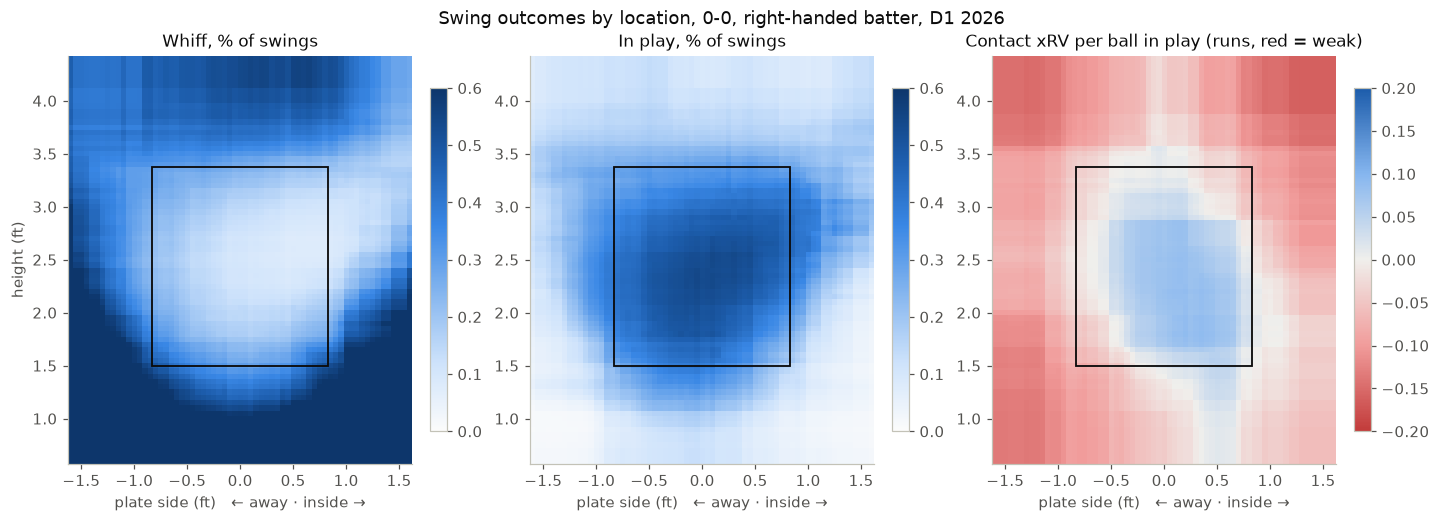

┌─────────────┬─────────┬────────┬──────────┬─────────────┐
│ spot        ┆ p_whiff ┆ p_foul ┆ p_inplay ┆ xrv_contact │
│ ---         ┆ ---     ┆ ---    ┆ ---      ┆ ---         │
│ str         ┆ f64     ┆ f64    ┆ f64      ┆ f64         │
╞═════════════╪═════════╪════════╪══════════╪═════════════╡
│ middle      ┆ 0.103   ┆ 0.372  ┆ 0.524    ┆ 0.080       │
│ outer half  ┆ 0.148   ┆ 0.364  ┆ 0.488    ┆ 0.039       │
│ 0.5 in off  ┆ 0.233   ┆ 0.372  ┆ 0.396    ┆ -0.017      │
│ 2 balls off ┆ 0.445   ┆ 0.352  ┆ 0.203    ┆ -0.082      │
└─────────────┴─────────┴────────┴──────────┴─────────────┘


In [6]:
FAMS = ["Fastball", "Breaking", "Offspeed"]
MIX = (D26.filter(pl.col("PitchFamily") != "Unknown").group_by("Balls", "Strikes", "PitchFamily").agg(pl.len())
          .with_columns((pl.col("len") / pl.col("len").sum().over("Balls", "Strikes")).alias("w")).drop("len"))
PIECES = ["p_strike", "p_swing", "ev_take", "ev_swing", "ev_swing_cx", "p_whiff", "p_foul", "p_inplay",
          "xrv_contact", "rv_strike", "rv_ball"]


def at(b, s, side, height, batter_side=0):
    """Mix-averaged model pieces for pitches at (side, height) in one count. One row per point."""
    side, height = (np.atleast_1d(np.asarray(a, float)) for a in np.broadcast_arrays(side, height))
    n = len(side)
    fr = pl.DataFrame({"pt": np.tile(np.arange(n), 3), "PlateLocHeight": np.tile(height, 3),
                       "PlateLocSide": np.tile(side, 3), "PitchFamily": np.repeat(FAMS, n)}).with_columns(
        pl.lit(batter_side).cast(pl.Int8).alias("BatterSide"), pl.lit(b).cast(D26["Balls"].dtype).alias("Balls"),
        pl.lit(s).cast(D26["Strikes"].dtype).alias("Strikes"), pl.col("PitchFamily").cast(pl.Enum(eye_v1.FAM_CATS)))
    c = CX.predict(BASE.components(fr)).join(MIX, on=["Balls", "Strikes", "PitchFamily"])
    return (c.group_by("pt").agg([((pl.col(k) * pl.col("w")).sum() / pl.col("w").sum()).alias(k) for k in PIECES])
             .sort("pt"))


def draw_zone(ax):
    ax.add_patch(Rectangle((-ZONE["h"], ZONE["b"]), 2 * ZONE["h"], ZONE["t"] - ZONE["b"], fill=False, lw=1.2, color=INK))
    ax.set_aspect("equal")
    ax.set_xlabel("plate side (ft)   ← away · inside →")


XS, ZS = np.linspace(-1.6, 1.6, 65), np.linspace(0.6, 4.4, 77)
GX, GZ = np.meshgrid(XS, ZS)
g00 = at(0, 0, GX.ravel(), GZ.ravel())
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), constrained_layout=True)
for ax, (col, title, cmap, kw) in zip(axes, [
        ("p_whiff", "Whiff, % of swings", SEQ, dict(vmin=0, vmax=0.6)),
        ("p_inplay", "In play, % of swings", SEQ, dict(vmin=0, vmax=0.6)),
        ("xrv_contact", "Contact xRV per ball in play (runs, red = weak)", DIV, dict(vmin=-0.2, vmax=0.2))]):
    im = ax.pcolormesh(GX, GZ, g00[col].to_numpy().reshape(GX.shape), cmap=cmap.reversed() if col == "xrv_contact" else cmap,
                       shading="auto", **kw)
    draw_zone(ax)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8)
axes[0].set_ylabel("height (ft)")
fig.suptitle("Swing outcomes by location, 0-0, right-handed batter, D1 2026", color=INK)
plt.show()

edge = at(0, 0, [0.0, -ZONE["h"] / 2, -(ZONE["h"] + 0.5 / 12), -(ZONE["h"] + 2 * BALL)], MID)
print(edge.with_columns(pl.Series("spot", ["middle", "outer half", "0.5 in off", "2 balls off"]))
          .select("spot", "p_whiff", "p_foul", "p_inplay", "xrv_contact"))

**Outer-edge contact is worse, as a coach would expect.** At 0-0 and mid height, a ball put in play is worth:

| Spot | Contact xRV (runs) | Whiff rate |
|---|---|---|
| Middle | +0.080 | 10% |
| Outer half | +0.039 | 15% |
| 0.5 in off the edge | −0.017 | 23% |
| Two balls off | −0.082 | 45% |

The question is whether v1 already knew this.

### 1c. EV(swing) rebuilt from its parts

Is the contact-built EV(swing) as accurate as v1's? Both are fit on 80% of 2026 games and checked against the realized run value of every swing in the other 20%. One swing's run value is mostly contact luck, so R² is tiny for both. What matters is calibration: within each decile of the prediction, does the mean prediction match the mean result?

In [7]:
sw26 = D26.filter(pl.col("is_verified"), pl.col("swung") == 1, pl.col("run_value").is_not_null())
tr_i, te_i = next(GroupShuffleSplit(1, test_size=0.2, random_state=0)
                  .split(np.zeros(sw26.height), groups=sw26["GameUID"].to_numpy()))
tr, te = sw26[tr_i], sw26[te_i]
ip_tr = tr.filter(pl.col("outc") == 2)
ip_tr = ip_tr.with_columns(pl.Series("xrv_obs", contact_xrv(ip_tr, "2026", V26)))
v1_ev = lgb.LGBMRegressor(objective="regression", n_estimators=eye_v1.N_TREES["ev"], **eye_v1.LGB_PARAMS) \
           .fit(lgb_frame(tr), tr["run_value"].to_numpy())
cx_tr = SwingValue().fit(tr, ip_tr)
# predict v1 before the join: a polars join doesn't promise to keep row order
te_c = cx_tr.predict(te.with_columns(pl.Series("ev_swing", v1_ev.predict(lgb_frame(te))))
                       .join(crv26, on=["Balls", "Strikes"], how="left"))
yv = te_c["run_value"].to_numpy()
for col, name in [("ev_swing", "v1, realized run value"), ("ev_swing_cx", "contact-built")]:
    pred = te_c[col].to_numpy()
    dec_ = te_c.with_columns(pl.col(col).qcut(10, labels=[str(i) for i in range(10)], allow_duplicates=True).alias("dec")) \
               .group_by("dec").agg(pl.col(col).mean().alias("pred"), pl.col("run_value").mean().alias("real"))
    gap = (dec_["pred"] - dec_["real"]).abs().max()
    print(f"{name:24s} held-out R² {1 - ((yv - pred) ** 2).mean() / yv.var():.4f}   "
          f"largest decile gap {gap:.4f} runs   spread of predictions (SD) {pred.std():.4f}")

v1, realized run value   held-out R² 0.0195   largest decile gap 0.0060 runs   spread of predictions (SD) 0.0598
contact-built            held-out R² 0.0200   largest decile gap 0.0040 runs   spread of predictions (SD) 0.0637


**v1 already knew it.**

- The contact-built EV(swing) is marginally better on held-out games: R² 0.0200 vs 0.0195, and its largest decile gap is 0.004 runs vs 0.006.
- The two agree almost everywhere; the solid and dashed blue lines in 1e lie on top of each other.
- v1's target, realized run value, already contained the weak outer-edge contact. The contact model only takes the fielding luck out of it.

### 1d. The test plate appearance, rescored

This is the same plate appearance as last time: a right-handed batter, pitch type unknown (league mix by count), with the 2-1 pitch placed at mid-height on the outer half. The models are now the v1.1 population (bunts out, refit), so the v1 column moves a little from the shipped-artifact numbers.

In [8]:
H_ = ZONE["h"]
PA = [("0-0 take, 0.5 in off outside", 0, 0, 0, -(H_ + 0.5 / 12), MID),
      ("1-0 take, in the dirt", 1, 0, 0, -0.74, 0.53),
      ("2-0 swing, lower half", 2, 0, 1, 0.0, ZONE["b"] + (MID - ZONE["b"]) / 2),
      ("2-1 swing, outer half", 2, 1, 1, -H_ / 2, MID),
      ("2-2 take, 1 ball above", 2, 2, 0, 0.0, ZONE["t"] + BALL),
      ("3-2 (1) K swinging, middle", 3, 2, 1, 0.0, MID),
      ("3-2 (2) K looking, middle", 3, 2, 0, 0.0, MID),
      ("3-2 (3) BB, takes 2 balls off", 3, 2, 0, -(H_ + 2 * BALL), MID),
      ("3-2 (4) BB, takes 0.5 in off", 3, 2, 0, -(H_ + 0.5 / 12), MID)]

rows = []
for lab, b, s, swung, x, z in PA:
    c = at(b, s, x, z).row(0, named=True)
    in_rule = abs(x) <= H_ and ZONE["b"] <= z <= ZONE["t"]
    take_rule = c["rv_strike"] if in_rule else c["rv_ball"]
    dev = swung - c["p_swing"]
    rows.append({"pitch": lab, "P(strike call)": c["p_strike"], "league swing": c["p_swing"],
                 "xRV contact": c["xrv_contact"], "EV take": c["ev_take"], "EV swing v1": c["ev_swing"],
                 "EV swing cx": c["ev_swing_cx"], "EV take rule": take_rule,
                 "eye": dev * (c["ev_swing"] - c["ev_take"]), "eye_cx": dev * (c["ev_swing_cx"] - c["ev_take"]),
                 "eye_rule": dev * (c["ev_swing"] - take_rule), "eye_both": dev * (c["ev_swing_cx"] - take_rule)})
TEST = pl.DataFrame(rows)
print(TEST.select("pitch", "P(strike call)", "league swing", "xRV contact", "EV take", "EV swing v1", "EV swing cx",
                  "eye", "eye_cx"))

shared = TEST.head(5).select(list(VARIANTS)).sum()
totals = pl.concat([shared + TEST[i].select(list(VARIANTS)) for i in range(5, 9)]) \
           .with_columns(pl.Series("scenario", [r[0][4:] for r in PA[5:]])).select("scenario", *VARIANTS)
print("\nPlate-appearance totals (first five pitches + the 3-2 pitch):")
print(totals.select("scenario", "eye", "eye_cx"))

┌───────────────────────────────┬────────────────┬──────────────┬─────────────┬─────────┬─────────────┬─────────────┬────────┬────────┐
│ pitch                         ┆ P(strike call) ┆ league swing ┆ xRV contact ┆ EV take ┆ EV swing v1 ┆ EV swing cx ┆ eye    ┆ eye_cx │
│ ---                           ┆ ---            ┆ ---          ┆ ---         ┆ ---     ┆ ---         ┆ ---         ┆ ---    ┆ ---    │
│ str                           ┆ f64            ┆ f64          ┆ f64         ┆ f64     ┆ f64         ┆ f64         ┆ f64    ┆ f64    │
╞═══════════════════════════════╪════════════════╪══════════════╪═════════════╪═════════╪═════════════╪═════════════╪════════╪════════╡
│ 0-0 take, 0.5 in off outside  ┆ 0.903          ┆ 0.325        ┆ -0.017      ┆ -0.068  ┆ -0.064      ┆ -0.057      ┆ -0.001 ┆ -0.004 │
│ 1-0 take, in the dirt         ┆ 0.009          ┆ 0.096        ┆ -0.177      ┆ 0.104   ┆ -0.105      ┆ -0.102      ┆ 0.020  ┆ 0.020  │
│ 2-0 swing, lower half         ┆ 0.994         

**Adding contact xRV moves every pitch by 0.016 runs or less.**

- Scenario 4's 3-2 take goes from −0.229 to −0.213.
- The ranking of the four plate appearances doesn't change: 3 > 1 > 4 > 2.
- Weaker outer-edge contact does lower EV(swing) at that spot (−0.095 → −0.114). That makes the take look slightly less bad, but not nearly enough to flip it.

### 1e. Why the 3-2 borderline take still loses

Eye compares swinging and taking **at the same pitch**. Outer-edge contact is worse than middle contact, but at 3-2 the alternative to swinging is a take that the D1 umpire calls strike three most of the time. The chart is a slice across the plate at mid height, 3-2, right-handed batter. It shows the value of each action at each spot.

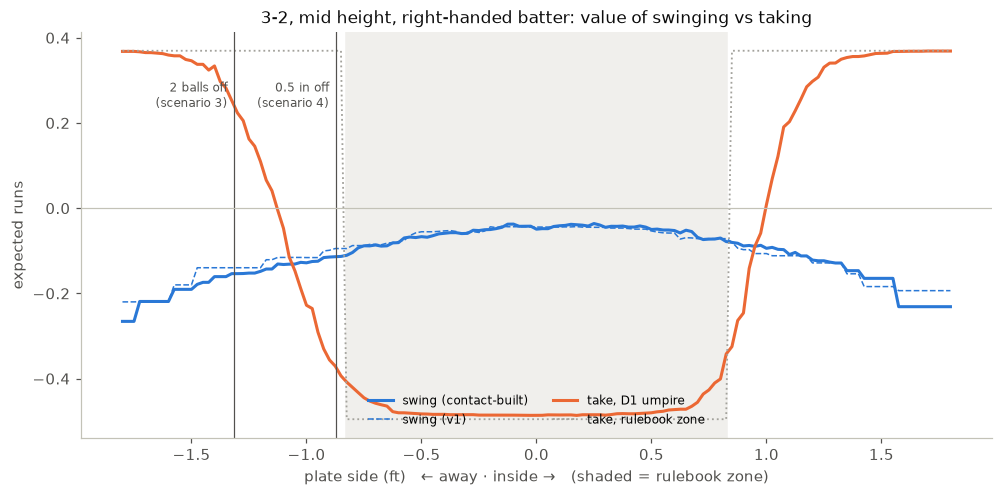

3-2 values: walk +0.369, strikeout -0.495, swing at 0.5 in off -0.114
Taking is the better call only if the umpire calls that pitch a strike less than 56% of the time; the model says 86%.
Even if every ball put in play there were an out, swinging would be worth -0.298 vs taking -0.372.


In [9]:
xs = np.linspace(-1.8, 1.8, 145)
sl = at(3, 2, xs, MID)
rule_take = np.where(np.abs(xs) <= H_, sl["rv_strike"].to_numpy(), sl["rv_ball"].to_numpy())
fig, ax = plt.subplots(figsize=(9, 4.4), constrained_layout=True)
ax.plot(xs, sl["ev_swing_cx"], color=BLUE, lw=2, label="swing (contact-built)")
ax.plot(xs, sl["ev_swing"], color=BLUE, lw=1, ls="--", label="swing (v1)")
ax.plot(xs, sl["ev_take"], color=ORANGE, lw=2, label="take, D1 umpire")
ax.plot(xs, rule_take, color=GRAY, lw=1.2, ls=":", label="take, rulebook zone")
for x0, lab in [(-(H_ + 0.5 / 12), "0.5 in off\n(scenario 4)"), (-(H_ + 2 * BALL), "2 balls off\n(scenario 3)")]:
    ax.axvline(x0, color=MUTED, lw=0.8)
    ax.text(x0 - 0.03, 0.3, lab, ha="right", va="top", fontsize=8, color=MUTED)
ax.axvspan(-H_, H_, color="#f0efec", zorder=0)
ax.axhline(0, color="#c3c2b7", lw=0.8)
ax.set_xlabel("plate side (ft)   ← away · inside →   (shaded = rulebook zone)")
ax.set_ylabel("expected runs")
ax.set_title("3-2, mid height, right-handed batter: value of swinging vs taking")
ax.legend(frameon=False, fontsize=8, loc="lower center", ncol=2)
plt.show()

s4 = at(3, 2, -(H_ + 0.5 / 12), MID).row(0, named=True)
be = (s4["rv_ball"] - s4["ev_swing_cx"]) / (s4["rv_ball"] - s4["rv_strike"])
print(f"3-2 values: walk {s4['rv_ball']:+.3f}, strikeout {s4['rv_strike']:+.3f}, swing at 0.5 in off {s4['ev_swing_cx']:+.3f}")
print(f"Taking is the better call only if the umpire calls that pitch a strike less than {be:.0%} of the time; "
      f"the model says {s4['p_strike']:.0%}.")
worst = s4["p_whiff"] * s4["rv_strike"] + s4["p_inplay"] * V26[3, 2, 0]
print(f"Even if every ball put in play there were an out, swinging would be worth {worst:+.3f} vs taking {s4['ev_take']:+.3f}.")

**Real outcomes, no models.** These are all 3-2 pitches at mid height (2.0–2.9 ft), D1 2022–2026, both sides of the plate, grouped by how far off the **outer** edge they crossed. Each group shows the realized run value of the swings and of the takes.

In [10]:
bins = [-6, -2, 0, 1, 2, 3, 5, 8]
labels = ["2-6 in inside the edge", "0-2 in inside the edge", "0-1 in off", "1-2 in off", "2-3 in off", "3-5 in off", "5-8 in off"]
real = (EDGE_32.filter(pl.col("off_in").is_between(-6, 8, closed="left"), pl.col("run_value").is_not_null())
          .with_columns(pl.col("off_in").cut(bins[1:-1], labels=labels, left_closed=True).alias("spot"))
          .group_by("spot").agg(
              (pl.col("swung") == 0).sum().alias("takes"),
              (pl.col("PitchCall") == "StrikeCalled").filter(pl.col("swung") == 0).mean().alias("called K %"),
              pl.col("run_value").filter(pl.col("swung") == 0).mean().alias("take RV"),
              (pl.col("swung") == 1).sum().alias("swings"),
              pl.col("run_value").filter(pl.col("swung") == 1).mean().alias("swing RV"))
          .with_columns((pl.col("swing RV") - pl.col("take RV")).alias("swing − take"))
          .sort(pl.col("spot").cast(pl.String).replace_strict({l: i for i, l in enumerate(labels)})))
print(real)

┌────────────────────────┬───────┬────────────┬─────────┬────────┬──────────┬──────────────┐
│ spot                   ┆ takes ┆ called K % ┆ take RV ┆ swings ┆ swing RV ┆ swing − take │
│ ---                    ┆ ---   ┆ ---        ┆ ---     ┆ ---    ┆ ---      ┆ ---          │
│ enum                   ┆ u32   ┆ f64        ┆ f64     ┆ u32    ┆ f64      ┆ f64          │
╞════════════════════════╪═══════╪════════════╪═════════╪════════╪══════════╪══════════════╡
│ 2-6 in inside the edge ┆ 1437  ┆ 0.981      ┆ -0.468  ┆ 19229  ┆ -0.069   ┆ 0.398        │
│ 0-2 in inside the edge ┆ 1031  ┆ 0.920      ┆ -0.422  ┆ 7620   ┆ -0.090   ┆ 0.333        │
│ 0-1 in off             ┆ 616   ┆ 0.880      ┆ -0.374  ┆ 3136   ┆ -0.100   ┆ 0.274        │
│ 1-2 in off             ┆ 683   ┆ 0.766      ┆ -0.282  ┆ 2679   ┆ -0.120   ┆ 0.162        │
│ 2-3 in off             ┆ 724   ┆ 0.627      ┆ -0.163  ┆ 2248   ┆ -0.119   ┆ 0.044        │
│ 3-5 in off             ┆ 1748  ┆ 0.395      ┆ 0.031   ┆ 3403   ┆ -0.

**The 3-2 borderline take loses because of the umpire, not the contact.**

- **The model:** swinging at the 0.5 in pitch at 3-2 is worth −0.114 runs. Taking it is worth −0.372, because D1 umpires call it strike three 86% of the time. Taking only wins when that chance is under 56%.
- **Even in the worst case:** if every ball put in play there were an out, swinging would still win (−0.298 vs −0.372).
- **Real outcomes, no model:** at 3-2, 0–1 in off the outer edge, there were 616 takes. 88% were called strike three, for −0.374 runs per take. The 3,136 swings averaged −0.100.
- **Where it flips:** swinging stays the better result out to about 3 in off (at 2–3 in it still wins by +0.044). From 3 in on, taking wins.

So at 3-2, D1 umpires call strikes about 3 in past the rulebook edge, and v1 grades hitters against the zone that actually gets called.

The coach's premise is right: outer-edge swings make weak contact. The conclusion, to take that pitch, isn't right at 3-2 in D1.

### 1f. A rulebook-zone version of eye

Question 2 is about what eye **means**, not about contact. v1 prices a take by the chance the **D1 umpire** calls it a strike. That makes eye "run value of decisions in the games as they are umpired." A batter who protects against a borderline pitch at 3-2 earns credit, and one who takes it is debited.

The alternative prices a take by the **rulebook zone**: a pitch outside the box is a ball, inside is a strike, whatever the umpire does. That makes eye "zone recognition." Laying off the 0.5 in pitch at 3-2 becomes the right call, and chasing it to fight it off becomes the wrong one. Only EV(take) changes: `ev_take_rule = rv_strike` inside the box and `rv_ball` outside it.

In [11]:
print(TEST.select("pitch", "P(strike call)", "league swing", "EV take", "EV take rule", "eye", "eye_rule", "eye_both"))
print("\nPlate-appearance totals:")
print(totals)

┌───────────────────────────────┬────────────────┬──────────────┬─────────┬──────────────┬────────┬──────────┬──────────┐
│ pitch                         ┆ P(strike call) ┆ league swing ┆ EV take ┆ EV take rule ┆ eye    ┆ eye_rule ┆ eye_both │
│ ---                           ┆ ---            ┆ ---          ┆ ---     ┆ ---          ┆ ---    ┆ ---      ┆ ---      │
│ str                           ┆ f64            ┆ f64          ┆ f64     ┆ f64          ┆ f64    ┆ f64      ┆ f64      │
╞═══════════════════════════════╪════════════════╪══════════════╪═════════╪══════════════╪════════╪══════════╪══════════╡
│ 0-0 take, 0.5 in off outside  ┆ 0.903          ┆ 0.325        ┆ -0.068  ┆ 0.073        ┆ -0.001 ┆ 0.044    ┆ 0.042    │
│ 1-0 take, in the dirt         ┆ 0.009          ┆ 0.096        ┆ 0.104   ┆ 0.106        ┆ 0.020  ┆ 0.020    ┆ 0.020    │
│ 2-0 swing, lower half         ┆ 0.994          ┆ 0.583        ┆ -0.108  ┆ -0.110       ┆ 0.007  ┆ 0.008    ┆ 0.010    │
│ 2-1 swing, outer half 

**Rulebook takes give a coach's ranking.**

- Scenario 4's take earns +0.383, the most of any pitch in the plate appearance.
- The order becomes 4 > 3 > 1 > 2 (+0.652, +0.530, +0.287, −0.164).

The cost: the metric now credits a take that ends in strike three 88% of the time in real D1 games.

### 1g. Which version measures eye better?

Hitter-seasons with at least 200 decisions, D1 2022–2026. A metric of eye should be (1) **stable**, repeating year over year for the same hitter, and (2) **predictive** of what eye should produce next season: walks, fewer strikeouts, and runs. For chase %, lower is better, so its predictive correlations have the opposite sign.

In [12]:
def pairs(min_n=MIN_N):
    """Returning hitters: season t joined to season t+1 (suffix _next), >= min_n decisions in both."""
    return pl.concat([H[a].filter(pl.col("n") >= min_n).join(H[b].filter(pl.col("n") >= min_n), on="Batter", suffix="_next")
                      for a, b in zip(YEARS[:-1], YEARS[1:])])


P = pairs()
pool = pl.concat([H[y].filter(pl.col("n") >= MIN_N) for y in YEARS])
print(f"{P.height:,} returning hitter pairs; {pool.height:,} hitter-seasons")
r = lambda f, a, b: f.select(pl.corr(a, b)).item()
print(pl.DataFrame([{"metric": VARIANTS.get(m, "chase %"), "SD per 100": pool[m].std() if m != "chase" else None,
                     "r with v1": r(pool, m, "eye"), "r with chase": r(pool, m, "chase"),
                     "year-over-year r": r(P, m, m + "_next"),
                     "→ next BB%": r(P, m, "bb_next"), "→ next K%": r(P, m, "k_next"),
                     "→ next RV/100": r(P, m, "rv100_next")} for m in [*VARIANTS, "chase"]]))

4,255 returning hitter pairs; 11,541 hitter-seasons
┌────────────────┬────────────┬───────────┬──────────────┬──────────────────┬────────────┬───────────┬───────────────┐
│ metric         ┆ SD per 100 ┆ r with v1 ┆ r with chase ┆ year-over-year r ┆ → next BB% ┆ → next K% ┆ → next RV/100 │
│ ---            ┆ ---        ┆ ---       ┆ ---          ┆ ---              ┆ ---        ┆ ---       ┆ ---           │
│ str            ┆ f64        ┆ f64       ┆ f64          ┆ f64              ┆ f64        ┆ f64       ┆ f64           │
╞════════════════╪════════════╪═══════════╪══════════════╪══════════════════╪════════════╪═══════════╪═══════════════╡
│ v1 (bunts out) ┆ 0.568      ┆ 1.000     ┆ -0.794       ┆ 0.552            ┆ 0.317      ┆ -0.106    ┆ 0.089         │
│ contact xRV    ┆ 0.581      ┆ 0.998     ┆ -0.796       ┆ 0.553            ┆ 0.318      ┆ -0.104    ┆ 0.087         │
│ rulebook takes ┆ 0.679      ┆ 0.964     ┆ -0.840       ┆ 0.541            ┆ 0.321      ┆ -0.086    ┆ 0.073       

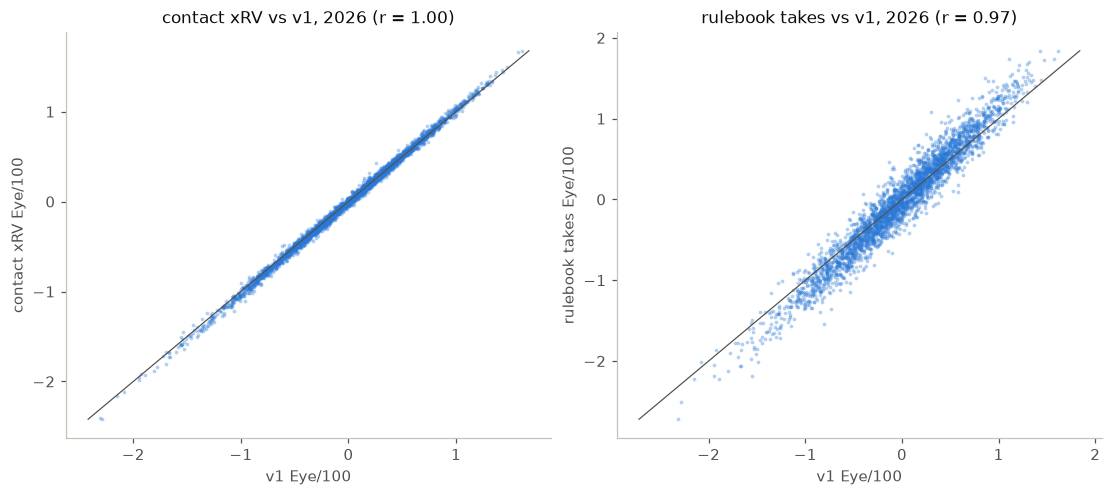

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), constrained_layout=True)
h26 = H["2026"].filter(pl.col("n") >= MIN_N)
for ax, m in zip(axes, ["eye_cx", "eye_rule"]):
    ax.scatter(h26["eye"], h26[m], s=6, color=BLUE, alpha=0.35, lw=0)
    lim = [min(h26["eye"].min(), h26[m].min()), max(h26["eye"].max(), h26[m].max())]
    ax.plot(lim, lim, color=MUTED, lw=0.8)
    ax.set_xlabel("v1 Eye/100")
    ax.set_ylabel(f"{VARIANTS[m]} Eye/100")
    ax.set_title(f"{VARIANTS[m]} vs v1, 2026 (r = {r(h26, 'eye', m):.2f})")
plt.show()

**Neither change makes eye a better measure.**

- **Contact xRV:** the same metric. r = 0.998 with v1, and every column is within 0.002.
- **Rulebook takes:** a slightly different metric (r = 0.964 with v1) that moves toward chase % (r with chase goes from −0.79 to −0.84). Compared with v1:
  - slightly less stable: year-over-year 0.541 vs 0.552;
  - about the same on next-season BB%: 0.321 vs 0.317;
  - slightly worse on next-season K% (−0.086 vs −0.106) and RV/100 (0.073 vs 0.089).
- **How big are the gaps?** With 4,255 pairs, one standard error on r is about 0.015, so these gaps are small. The fair reading is "no better", not "clearly worse".
- **Against chase %:** chase is still the most stable (0.606) and the best predictor of next-season walks (−0.374). Eye's edge over chase is K% and RV/100, and the rulebook version gives back part of that edge.

One caveat: the rulebook box is a hard edge, and TrackMan locations carry some measurement error. A softened edge might do a little better, but it can't change the verdict on a pitch the umpire calls a strike 86% of the time.

### Section 1 summary

1. **Contact xRV by location is real, but v1 already has it.** Outer-edge contact is weaker: at 0-0 it falls from +0.080 in the middle to −0.017 at 0.5 in off. v1's EV(swing) learned this from realized run values, so making it explicit barely changes hitter eye (r = 0.998).
   - It's still worth keeping as an explanation tool. Splitting a swing into whiff, foul, in-play and contact xRV is easier to defend to a coach than one number.
   - It is marginally better calibrated.
   - It does not change scenario 4.
2. **Scenario 4 is penalized because D1 umpires call that 3-2 pitch strike three 86–88% of the time.** Taking only beats swinging when that chance is under about 56%. At 3-2 that happens about 3 in off the edge.
3. **Rulebook takes reproduce the coach's ranking but not a better metric.** That version is slightly less stable, slightly worse at predicting K% and runs, and closer to chase %.
4. **Recommendation for v1.1 (open):** keep the umpire zone for Eye. If coaches want a "zone recognition" number, the rulebook version could ship as a separate, labeled stat next to Eye rather than replace it.